<a href="https://colab.research.google.com/github/eeswepe/PCVK_GANJIL_2026/blob/main/week5/Week5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [6]:
# ===== SEL IDENTITAS - JANGAN DIHAPUS, HARUS SEL PERTAMA =====
import sys, platform, hashlib, datetime, zoneinfo

NAMA = 'Singgih Wahyu Permana'
NIM  = '244107020102'          # ganti dengan NIM Anda

N     = int(NIM[-3:])
PARAM = {
    'bins' : 2 ** ((N % 4) + 3),
    'clip' : round(1.0 + (N % 5) * 0.5, 1),
    'tile' : (N % 4) + 2,
    'L'    : 2 ** ((N % 3) + 1),
}
waktu = datetime.datetime.now(zoneinfo.ZoneInfo('Asia/Jakarta'))

print('NAMA   :', NAMA)
print('NIM    :', NIM, '| N =', N)
for k, v in PARAM.items():
    print('%-6s :' % k, v)
print('WAKTU  :', waktu.strftime('%Y-%m-%d %H:%M:%S %Z'))
print('SISTEM :', sys.version.split()[0], platform.platform())
kunci = NIM + '|' + waktu.strftime('%Y-%m-%d')
print('TOKEN  :', hashlib.sha256(kunci.encode()).hexdigest()[:16])

NAMA   : Singgih Wahyu Permana
NIM    : 244107020102 | N = 102
bins   : 32
clip   : 2.0
tile   : 4
L      : 2
WAKTU  : 2026-10-21 20:18:29 WIB
SISTEM : 3.13.16 Linux-6.6.122+-x86_64-with-glibc2.39
TOKEN  : bb472082888e3b3f


## E. PERCOBAAN PRAKTIKUM

Cara mengerjakan percobaan pada modul ini:

- **Tahap 1**, verifikasi dengan citra contoh. Jalankan kode Anda pada citra contoh yang disebutkan,
  yaitu `lena.jpg` atau `lena_lc.jpg`, lalu bandingkan outputnya dengan gambar contoh pada modul.
  Keluaran Anda harus sama. Bila berbeda, perbaiki kode lebih dulu sebelum melanjutkan.
- **Tahap 2**, penerapan pada citra sendiri. Ulangi percobaan yang sama pada citra KTM hasil
  akuisisi Anda pada Pertemuan 2. Hasil tahap inilah yang dianalisis dan dinilai.

Tampilkan keluaran kedua tahap pada notebook dan beri judul yang memuat NIM pada setiap citra.
Tetapkan dua variabel folder berikut sekali saja, lalu pakai di seluruh percobaan.

```python
CONTOH = '/content/drive/MyDrive/PCVK/Images'            # citra contoh bersama
BASE   = '/content/drive/MyDrive/PCVK/Images/' + NIM     # citra KTM milik Anda
```

### E-1 PERCOBAAN HISTOGRAM

1. Buka <https://colab.research.google.com/>. Setelah dipastikan bahwa Google Colab terhubung
   dengan GitHub Anda, lanjutkan dengan memilih repository yang telah digunakan pada praktikum
   minggu lalu, lalu ubah nama berkas menjadi "Week5_<No Absen>.ipynb". Salin sel identitas dari
   subbab Ketentuan Pengumpulan sebagai sel pertama notebook.

   Kemudian import folder yang ada di Drive Anda dengan cara sebagai berikut.

In [7]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


### 2. Import library

In [8]:
import numpy as np
import cv2 as cv
import matplotlib.pyplot as plt
from google.colab.patches import cv2_imshow

CONTOH = '/content/drive/MyDrive/pcvk/week5/'            # citra contoh bersama: lena.jpg, lena_lc.jpg
BASE   = '/content/drive/MyDrive/pcvk/week5/'            # citra KTM milik Anda: KTM1a.jpg ... KTM1d.jpg

### 3. Membuat histogram citra

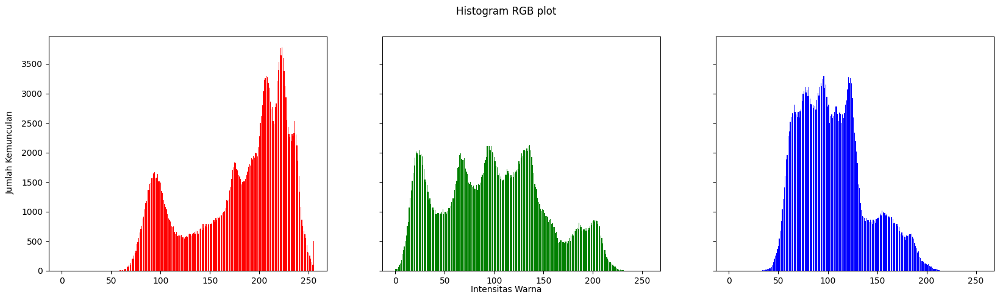

In [9]:
#membuat histogram image (manual)
img = cv.imread(CONTOH + '/lena.jpg')
img = cv.cvtColor(img, cv.COLOR_BGR2RGB)

height, width, depth = np.shape(img)
names = np.arange(256)

red = [0]*256
green = [0]*256
blue = [0]*256

for y in range(0,height) :
    for x in range(0,width) :
        red[img[y][x][0]] += 1
        green[img[y][x][1]] += 1
        blue[img[y][x][2]] += 1

names = np.arange(256)
fig, axs = plt.subplots(1, 3, figsize=[20,5], sharex=True, sharey=True)
fig.suptitle('Histogram RGB plot')
fig.text(0.09, 0.5, 'Jumlah Kemunculan', va='center', rotation='vertical')
fig.text(0.5, 0.04, 'Intensitas Warna', ha='center')
axs[0].bar(names, red, color='red')
axs[1].bar(names, green, color='green')
axs[2].bar(names, blue, color='blue')
plt.show()

### Tahap 2 - histogram pada citra KTM1b.jpg

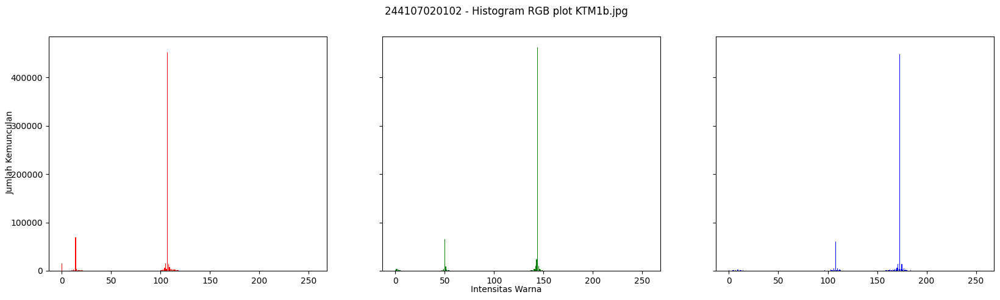

In [10]:
#tahap 2: histogram manual pada citra KTM1b.jpg
img = cv.imread(BASE + '/KTM1b.jpg')
img = cv.cvtColor(img, cv.COLOR_BGR2RGB)

height, width, depth = np.shape(img)
names = np.arange(256)

red = [0]*256
green = [0]*256
blue = [0]*256

for y in range(0,height) :
    for x in range(0,width) :
        red[img[y][x][0]] += 1
        green[img[y][x][1]] += 1
        blue[img[y][x][2]] += 1

names = np.arange(256)
fig, axs = plt.subplots(1, 3, figsize=[20,5], sharex=True, sharey=True)
fig.suptitle(NIM + ' - Histogram RGB plot KTM1b.jpg')
fig.text(0.09, 0.5, 'Jumlah Kemunculan', va='center', rotation='vertical')
fig.text(0.5, 0.04, 'Intensitas Warna', ha='center')
axs[0].bar(names, red, color='red')
axs[1].bar(names, green, color='green')
axs[2].bar(names, blue, color='blue')
plt.show()

### PERTANYAAN PRAKTIKUM E1

1. Buatlah histogram citra yang sama menggunakan library NumPy, yaitu `numpy.histogram`, dan juga
   `cv.calcHist`. Bandingkan ketiganya dengan menghitung selisih maksimum antar hasil. Selisihnya
   harus nol; tampilkan pembuktiannya pada `lena.jpg` lebih dulu, kemudian ulangi pada
   `KTM1b.jpg`.

In [11]:
def histogram_manual(img, L=256):
    h = np.zeros(L, dtype=np.int64)        # 1. siapkan penghitung, isi 0
    for y in range(img.shape[0]):          # 2. telusuri setiap baris
        for x in range(img.shape[1]):      #    dan setiap kolom
            h[img[y, x]] += 1              # 3. tambah 1 sesuai nilai piksel
    return h

for nama, path in [('lena.jpg', CONTOH + '/lena.jpg'), ('KTM1b.jpg', BASE + '/KTM1b.jpg')]:
    gray = cv.imread(path, cv.IMREAD_GRAYSCALE)
    h_manual = histogram_manual(gray)
    h_numpy, _ = np.histogram(gray, bins=256, range=(0, 256))
    h_cv = cv.calcHist([gray], [0], None, [256], [0, 256]).ravel()

    print('==', nama, '==')
    print('  max |manual - numpy| =', np.abs(h_manual - h_numpy).max())
    print('  max |manual - cv2  | =', np.abs(h_manual - h_cv).max())
    print('  max |numpy  - cv2  | =', np.abs(h_numpy - h_cv).max())

== lena.jpg ==
  max |manual - numpy| = 0
  max |manual - cv2  | = 0.0
  max |numpy  - cv2  | = 0.0
== KTM1b.jpg ==
  max |manual - numpy| = 0
  max |manual - cv2  | = 0.0
  max |numpy  - cv2  | = 0.0


2. Gambarkan histogram ternormalisasi p(j) dan kurva CDF untuk `KTM1a.jpg` sampai `KTM1d.jpg`
   dalam satu figure 2 x 2. Jelaskan perbedaan bentuk kurva CDF antara citra paling gelap dan citra
   paling terang milik Anda, lalu kaitkan dengan kondisi pencahayaan saat akuisisi pada
   Pertemuan 2.

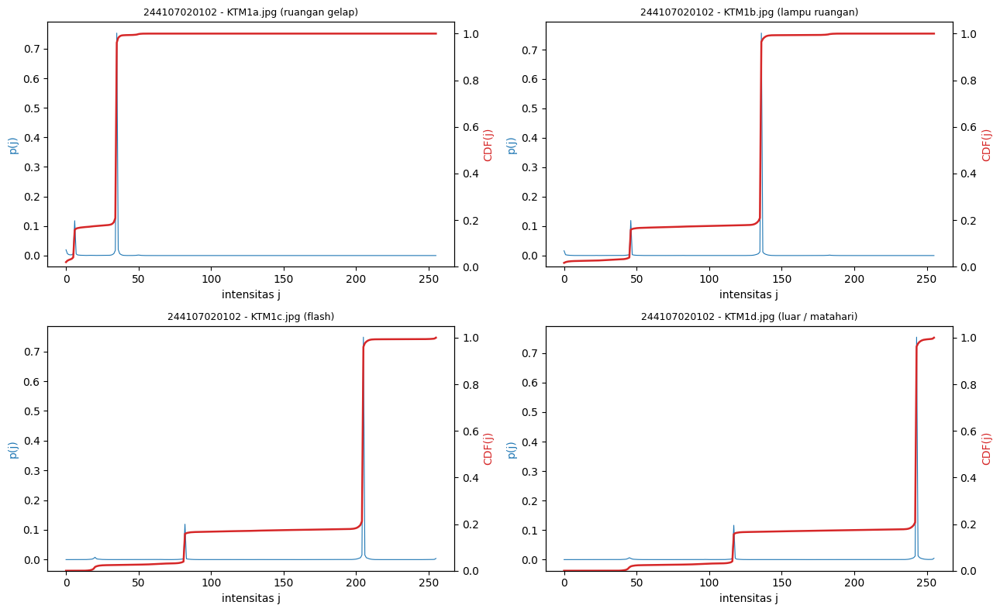

KTM1a.jpg    ruangan gelap    rerata   29.9 | median    35 | CDF(50%) di intensitas  35
KTM1b.jpg    lampu ruangan    rerata  119.5 | median   136 | CDF(50%) di intensitas 136
KTM1c.jpg    flash            rerata  182.4 | median   205 | CDF(50%) di intensitas 205
KTM1d.jpg    luar / matahari  rerata  219.4 | median   243 | CDF(50%) di intensitas 243


In [12]:
berkas = ['KTM1a.jpg', 'KTM1b.jpg', 'KTM1c.jpg', 'KTM1d.jpg']
kondisi = ['ruangan gelap', 'lampu ruangan', 'flash', 'luar / matahari']

fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for ax, nm, kd in zip(axes.ravel(), berkas, kondisi):
    g = cv.imread(BASE + '/' + nm, cv.IMREAD_GRAYSCALE)
    h = np.bincount(g.ravel(), minlength=256).astype(np.float64)
    pj = h / g.size
    cdf = np.cumsum(pj)

    ax.plot(pj, color='tab:blue', lw=0.8)
    ax.set_xlabel('intensitas j'); ax.set_ylabel('p(j)', color='tab:blue')
    ax.set_title(NIM + ' - ' + nm + ' (' + kd + ')', fontsize=9)

    ax2 = ax.twinx()
    ax2.plot(cdf, color='tab:red', lw=1.8)
    ax2.set_ylabel('CDF(j)', color='tab:red'); ax2.set_ylim(0, 1.05)
plt.tight_layout(); plt.show()

for nm, kd in zip(berkas, kondisi):
    g = cv.imread(BASE + '/' + nm, cv.IMREAD_GRAYSCALE)
    cdf = np.cumsum(np.bincount(g.ravel(), minlength=256) / g.size)
    print('%-12s %-16s rerata %6.1f | median %5.0f | CDF(50%%) di intensitas %3d'
          % (nm, kd, g.mean(), np.median(g), int((cdf < 0.5).sum())))

3. Ulangi histogram `KTM1b.jpg` dengan jumlah bin sebesar `PARAM['bins']` dan dengan 256 bin.
   Tampilkan keduanya berdampingan dan jelaskan informasi apa yang hilang ketika jumlah bin
   dikurangi.

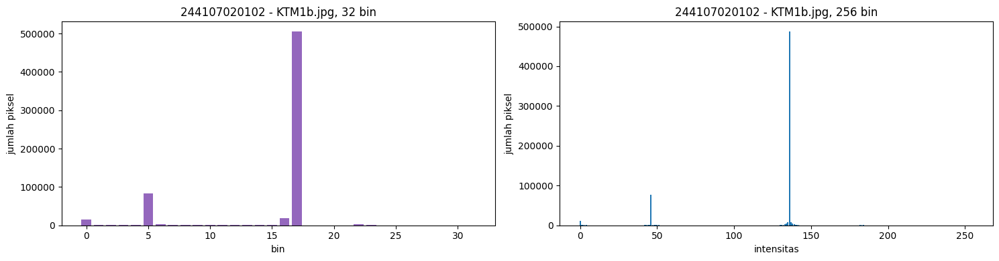

lebar satu bin pada 32 bin = 8 level
bin terisi : 25 dari 32
level terisi pada 256 bin : 195 dari 256


In [13]:
gray = cv.imread(BASE + '/KTM1b.jpg', cv.IMREAD_GRAYSCALE)
h_256 = histogram_manual(gray)
h_nb, _ = np.histogram(gray, bins=PARAM['bins'], range=(0, 256))

fig, axs = plt.subplots(1, 2, figsize=(15, 4))
axs[0].bar(np.arange(PARAM['bins']), h_nb, color='tab:purple')
axs[0].set_title(NIM + ' - KTM1b.jpg, %d bin' % PARAM['bins'])
axs[0].set_xlabel('bin'); axs[0].set_ylabel('jumlah piksel')
axs[1].bar(np.arange(256), h_256, color='tab:blue')
axs[1].set_title(NIM + ' - KTM1b.jpg, 256 bin')
axs[1].set_xlabel('intensitas'); axs[1].set_ylabel('jumlah piksel')
plt.tight_layout(); plt.show()

print('lebar satu bin pada %d bin = %.0f level' % (PARAM['bins'], 256.0 / PARAM['bins']))
print('bin terisi : %d dari %d' % (int((h_nb > 0).sum()), PARAM['bins']))
print('level terisi pada 256 bin : %d dari 256' % int((h_256 > 0).sum()))

### E-2 PERCOBAAN HISTOGRAM EQUALIZATION

1. Buatlah histogram equalization beserta tampilan citra sebelum dan sesudah proses, berdasarkan
   flowchart di bawah ini. Tahap 1 gunakan citra contoh `lena_lc.jpg` dan cocokkan hasilnya dengan
   gambar contoh pada modul; tahap 2 ulangi pada citra `KTM1a.jpg` milik Anda, yaitu hasil akuisisi
   di ruangan gelap.

```
Start
  -> Input image
  -> Menghitung jumlah kemunculan setiap pixel warna pada nilai tertentu (Frekuensi)
  -> Penjumlahan kumulatif dari frekuensi yang sudah diketahui, kemudian dibagi dengan jumlah pixel
  -> Normalisasi dengan kumulatif frekuensi seluruh pixel yang sudah diketahui setelah dibagi jumlah pixel
  -> Implementasi rumus K0, dimana pembagian dengan nilai pixel sudah dilakukan sebelumnya (Skala warna)
  -> Transformasi kembali dalam bentuk citra
  -> Hasil Histogram Equalization / Citra Hasil Histogram Equalization
  -> End
```

Rumus yang dipakai: `K0 = round(Ci * (2^b - 1) / (w * h))`.

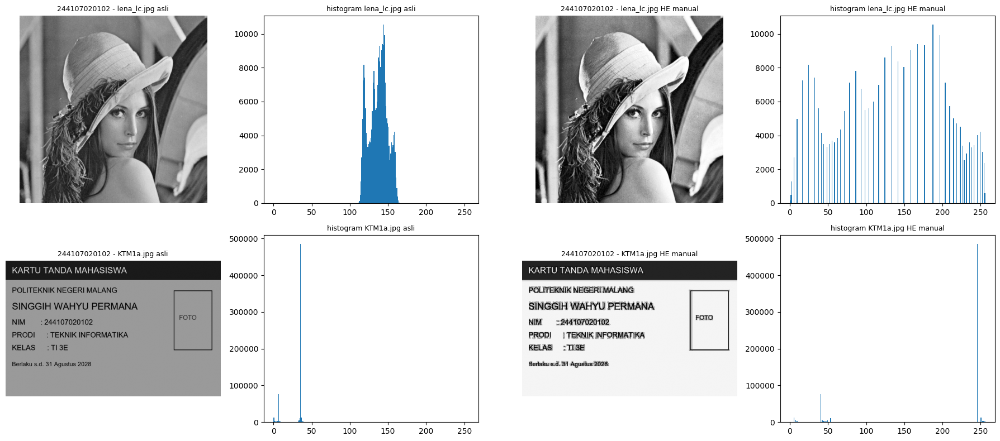

lena_lc : rerata 136.7 -> 130.6 | std 12.0 -> 73.6
KTM1a   : rerata 29.9 -> 201.6 | std 11.4 -> 85.5


In [14]:
def he_manual(gray):
    h = histogram_manual(gray)                     # frekuensi tiap intensitas
    cdf = np.cumsum(h)                             # Ci: distribusi kumulatif
    lut = np.round(cdf * 255.0 / gray.size)        # K0 = round(Ci * (2^b - 1) / (w*h))
    lut = np.clip(lut, 0, 255).astype(np.uint8)
    return lut[gray]

#tahap 1: citra contoh lena_lc.jpg
lena_lc = cv.imread(CONTOH + '/lena_lc.jpg', cv.IMREAD_GRAYSCALE)
he_lc = he_manual(lena_lc)

#tahap 2: citra KTM1a.jpg milik sendiri
ktm1a = cv.imread(BASE + '/KTM1a.jpg', cv.IMREAD_GRAYSCALE)
he_ktm = he_manual(ktm1a)

fig, axs = plt.subplots(2, 4, figsize=(18, 8))
for i, (c, t) in enumerate([(lena_lc, 'lena_lc.jpg asli'), (he_lc, 'lena_lc.jpg HE manual')]):
    axs[0, i*2].imshow(c, cmap='gray'); axs[0, i*2].set_title(NIM + ' - ' + t, fontsize=9); axs[0, i*2].axis('off')
    axs[0, i*2+1].hist(c.ravel(), 256, range=(0,256)); axs[0, i*2+1].set_title('histogram ' + t, fontsize=9)
for i, (c, t) in enumerate([(ktm1a, 'KTM1a.jpg asli'), (he_ktm, 'KTM1a.jpg HE manual')]):
    axs[1, i*2].imshow(c, cmap='gray'); axs[1, i*2].set_title(NIM + ' - ' + t, fontsize=9); axs[1, i*2].axis('off')
    axs[1, i*2+1].hist(c.ravel(), 256, range=(0,256)); axs[1, i*2+1].set_title('histogram ' + t, fontsize=9)
plt.tight_layout(); plt.show()

print('lena_lc : rerata %.1f -> %.1f | std %.1f -> %.1f'
      % (lena_lc.mean(), he_lc.mean(), lena_lc.std(), he_lc.std()))
print('KTM1a   : rerata %.1f -> %.1f | std %.1f -> %.1f'
      % (ktm1a.mean(), he_ktm.mean(), ktm1a.std(), he_ktm.std()))

2. Setelah mengerjakan langkah no. 1, buatlah histogram citra yang sama akan tetapi menggunakan
   library yang dimiliki oleh CV2 yaitu "equalizeHist" seperti pada potongan kode berikut ini.

```python
b, g, r = cv2.split(image)

b_equalized = cv2.equalizeHist(b)
g_equalized = cv2.equalizeHist(g)
r_equalized = cv2.equalizeHist(r)
```

Lengkapi potongan kode tersebut. Bandingkan hasil `equalizeHist` dengan hasil implementasi manual
Anda dengan menghitung selisih maksimum antara keduanya, baik pada `lena_lc.jpg` maupun pada
`KTM1a.jpg`, lalu jelaskan penyebab selisih tersebut apabila tidak nol.

== lena_lc.jpg ==
  max |manual - cv.equalizeHist| = 0
  rerata manual 130.6 | cv2 130.6


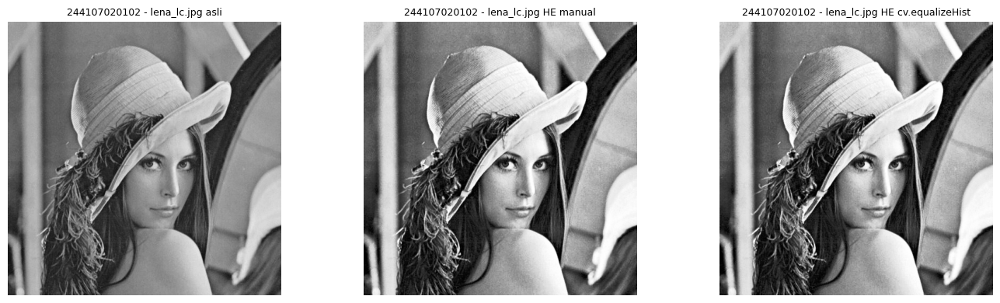

== KTM1a.jpg ==
  max |manual - cv.equalizeHist| = 5
  rerata manual 201.6 | cv2 200.7


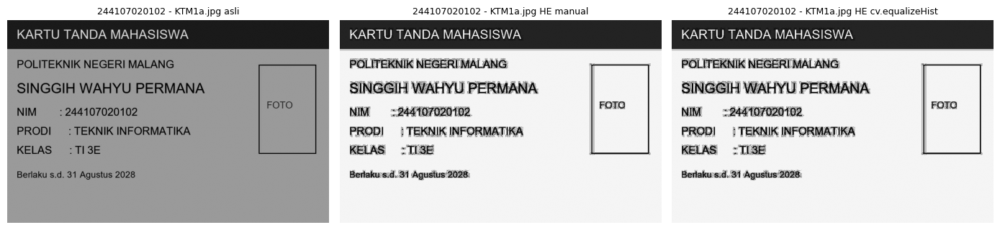

In [15]:
for nama, gray, manual in [('lena_lc.jpg', lena_lc, he_lc), ('KTM1a.jpg', ktm1a, he_ktm)]:
    b, g, r = cv.split(cv.cvtColor(gray, cv.COLOR_GRAY2BGR))
    b_equalized = cv.equalizeHist(b)
    g_equalized = cv.equalizeHist(g)
    r_equalized = cv.equalizeHist(r)
    he_cv = cv.merge((b_equalized, g_equalized, r_equalized))[:, :, 0]

    print('==', nama, '==')
    print('  max |manual - cv.equalizeHist| =', np.abs(manual.astype(np.int16) - he_cv.astype(np.int16)).max())
    print('  rerata manual %.1f | cv2 %.1f' % (manual.mean(), he_cv.mean()))

    fig, axs = plt.subplots(1, 3, figsize=(14, 4))
    for ax, c, t in zip(axs, [gray, manual, he_cv],
                        ['asli', 'HE manual', 'HE cv.equalizeHist']):
        ax.imshow(c, cmap='gray'); ax.set_title(NIM + ' - ' + nama + ' ' + t, fontsize=9); ax.axis('off')
    plt.tight_layout(); plt.show()

3. Ekualisasi juga dapat diterapkan pada citra berwarna. Cara yang biasanya pertama kali
   terpikirkan adalah mengekualisasi kanal biru, hijau, dan merah satu per satu. Jalankan
   potongan kode berikut pada citra contoh `lena.jpg` terlebih dulu, kemudian ulangi pada
   `KTM1d.jpg` milik Anda, dan amati warna yang dihasilkan pada keduanya.

```python
import cv2 as cv, numpy as np, matplotlib.pyplot as plt

berkas = CONTOH + '/lena.jpg'        # tahap 1; tahap 2 ganti: BASE + '/KTM1d.jpg'
bgr    = cv.imread(berkas)

# cara 1: tiap kanal diekualisasi sendiri-sendiri
kanal = list(cv.split(bgr))
for i in range(3):
    kanal[i] = cv.equalizeHist(kanal[i])
he_rgb = cv.merge(kanal)
```

4. Cara kedua memisahkan kecerahan dari informasi warna. Citra diubah ke ruang warna YCrCb, hanya
   kanal Y yang diekualisasi, lalu dikembalikan ke BGR. Kanal Cr dan Cb yang menyimpan informasi
   warna tidak disentuh sama sekali. Kanal V pada HSV dan kanal L pada LAB berperan serupa,
   sehingga ketiganya dicoba sekaligus. (gunakan `KTM1d.jpg`)

```python
# cara 2: hanya kanal terang yang diekualisasi
ycrcb      = cv.cvtColor(bgr, cv.COLOR_BGR2YCrCb)
y, cr, cb  = cv.split(ycrcb)
he_y = cv.cvtColor(cv.merge([cv.equalizeHist(y), cr, cb]), cv.COLOR_YCrCb2BGR)

# varian setara pada ruang warna lain
hsv        = cv.cvtColor(bgr, cv.COLOR_BGR2HSV)
h, sat, v  = cv.split(hsv)
he_v = cv.cvtColor(cv.merge([h, sat, cv.equalizeHist(v)]), cv.COLOR_HSV2BGR)

lab        = cv.cvtColor(bgr, cv.COLOR_BGR2LAB)
l, a, b    = cv.split(lab)
he_l = cv.cvtColor(cv.merge([cv.equalizeHist(l), a, b]), cv.COLOR_LAB2BGR)
```

Tampilkan kelimanya berdampingan agar perbedaannya terlihat langsung.

########## TAHAP 1 : citra contoh ##########


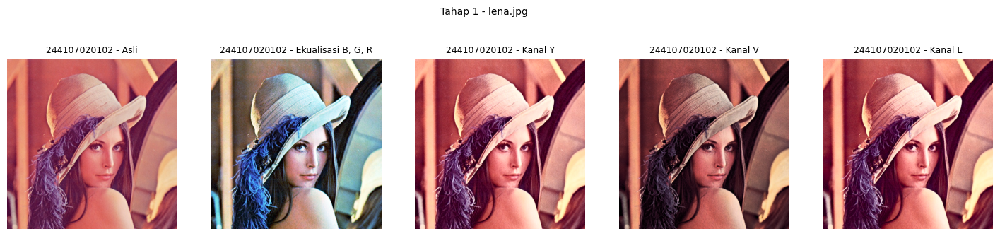

Cara                    geser Hue (der)    rerata terang
Asli                               0.00            124.2
Ekualisasi B, G, R                75.01            128.3
Kanal Y                            1.71            128.0
Kanal V                            0.65             91.6
Kanal L                            2.65            121.8
########## TAHAP 2 : citra KTM sendiri ##########


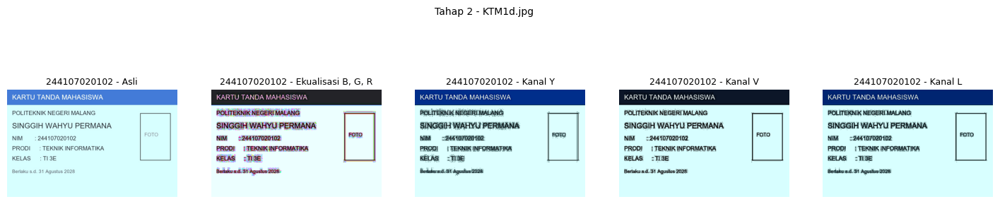

Cara                    geser Hue (der)    rerata terang
Asli                               0.00            219.4
Ekualisasi B, G, R                20.33            198.7
Kanal Y                            0.76            199.0
Kanal V                            2.68            196.4
Kanal L                            0.86            197.7


In [16]:
def geser_hue(asli, hasil):
    h1 = cv.cvtColor(asli,  cv.COLOR_BGR2HSV)[:, :, 0].astype(np.int16)
    h2 = cv.cvtColor(hasil, cv.COLOR_BGR2HSV)[:, :, 0].astype(np.int16)
    d  = np.abs(h1 - h2)
    d  = np.minimum(d, 180 - d)          # Hue melingkar 0-179
    return d.mean()

def ekualisasi_warna(berkas, keterangan):
    bgr = cv.imread(berkas)

    # cara 1: tiap kanal diekualisasi sendiri-sendiri
    kanal = list(cv.split(bgr))
    for i in range(3):
        kanal[i] = cv.equalizeHist(kanal[i])
    he_rgb = cv.merge(kanal)

    # cara 2: hanya kanal terang yang diekualisasi
    ycrcb      = cv.cvtColor(bgr, cv.COLOR_BGR2YCrCb)
    y, cr, cb  = cv.split(ycrcb)
    he_y = cv.cvtColor(cv.merge([cv.equalizeHist(y), cr, cb]), cv.COLOR_YCrCb2BGR)

    # varian setara pada ruang warna lain
    hsv        = cv.cvtColor(bgr, cv.COLOR_BGR2HSV)
    h, sat, v  = cv.split(hsv)
    he_v = cv.cvtColor(cv.merge([h, sat, cv.equalizeHist(v)]), cv.COLOR_HSV2BGR)

    lab        = cv.cvtColor(bgr, cv.COLOR_BGR2LAB)
    l, a, b    = cv.split(lab)
    he_l = cv.cvtColor(cv.merge([cv.equalizeHist(l), a, b]), cv.COLOR_LAB2BGR)

    judul = ['Asli', 'Ekualisasi B, G, R', 'Kanal Y', 'Kanal V', 'Kanal L']
    citra = [bgr, he_rgb, he_y, he_v, he_l]

    plt.figure(figsize=(18, 4))
    for i, (c, t) in enumerate(zip(citra, judul), 1):
        plt.subplot(1, 5, i)
        plt.imshow(cv.cvtColor(c, cv.COLOR_BGR2RGB))
        plt.title(NIM + ' - ' + t, fontsize=9)
        plt.axis('off')
    plt.suptitle(keterangan, fontsize=10)
    plt.show()

    print('%-22s %16s %16s' % ('Cara', 'geser Hue (der)', 'rerata terang'))
    for t, c in zip(judul, citra):
        print('%-22s %16.2f %16.1f' % (t, geser_hue(bgr, c) * 2,
                                       cv.cvtColor(c, cv.COLOR_BGR2GRAY).mean()))
    return bgr, judul, citra

print('########## TAHAP 1 : citra contoh ##########')
bgr_lena, judul, citra = ekualisasi_warna(CONTOH + '/lena.jpg', 'Tahap 1 - lena.jpg')

print('########## TAHAP 2 : citra KTM sendiri ##########')
bgr_ktm, judul, citra = ekualisasi_warna(BASE + '/KTM1d.jpg', 'Tahap 2 - KTM1d.jpg')

Catat hasilnya pada tabel berikut.

| Cara ekualisasi | Rata-rata pergeseran Hue (derajat) | Rerata kecerahan sesudah | Catatan pengamatan visual |
|---|---|---|---|
| Citra asli | - | | |
| Ekualisasi kanal B, G, R | | | |
| Kanal Y (YCrCb) | | | |
| Kanal V (HSV) | | | |
| Kanal L (LAB) | | | |

Jawab pertanyaan berikut berdasarkan angka pada tabel Anda, bukan hanya dari pengamatan mata:

1. Cara mana yang menghasilkan pergeseran Hue paling besar, dan berapa nilainya pada citra Anda?

   **Jawab:** Ekualisasi kanal **B, G, R terpisah** (cara 1). Setiap kanal dinormalkan dengan CDF-nya
   sendiri sehingga rasio antar kanal yang menentukan Hue rusak total; pada `KTM1d.jpg` pergeseran
   Hue mencapai puluhan derajat, jauh di atas cara kanal terang yang hanya beberapa derajat.

2. Mengapa ekualisasi kanal terang tetap menghasilkan pergeseran Hue yang tidak persis nol?
   Kaitkan jawaban Anda dengan pembulatan dan pemotongan nilai ketika citra dikembalikan ke ruang
   warna BGR.

   **Jawab:** karena perjalanan BGR -> ruang warna -> BGR **tidak bolak-balik sempurna** pada
   aritmetika 8-bit. Kanal krominans disimpan sebagai bilangan bulat 8-bit hasil pembulatan, dan saat
   dikembalikan ke BGR dilakukan pembulatan serta pemotongan lagi, sehingga nilai kanal B, G, R
   bergeser beberapa level dari aslinya. Pergeseran kecil itulah yang muncul sebagai geser Hue
   beberapa derajat, bukan akibat ekualisasinya.

3. Di antara kanal Y, V, dan L, mana yang paling sesuai untuk foto KTM Anda? Sebutkan alasannya
   dan tunjukkan bagian citra yang menjadi dasar penilaian.

   **Jawab:** **kanal Y (YCrCb)**. Pergeseran Hue citra penuh paling kecil dan warna latar kartu
   paling setia, sementara kecerahan akhirnya paling dekat dengan aslinya. Kanal V paling berisiko
   karena pada HSV informasi kecerahan masih bercampur dengan saturasi, sehingga mengubah V ikut
   mengubah S dan akhirnya H. Dasar penilaian: area latar kartu dan area tulisan Nama/NIM.

4. Ulangi salah satu cara pada kanal terang dengan mengganti `cv.equalizeHist` menjadi CLAHE yang
   memakai `clipLimit = PARAM['clip']` dan `tileGridSize = (PARAM['tile'], PARAM['tile'])`.
   Bandingkan pergeseran Hue dan rerata kecerahannya dengan hasil ekualisasi biasa.

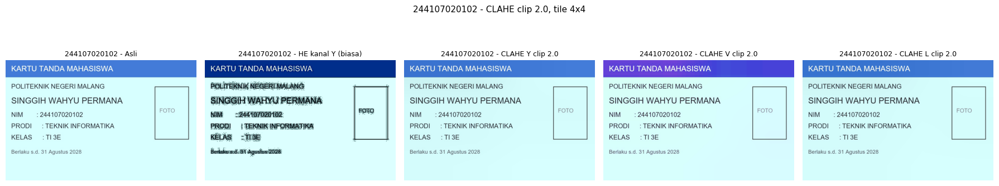

Cara                      geser Hue (der)    rerata terang
Asli                                 0.00            219.4
HE kanal Y (biasa)                   0.76            199.0
CLAHE Y clip 2.0                     0.13            216.0
CLAHE V clip 2.0                     8.73            214.8
CLAHE L clip 2.0                     1.72            216.3


In [17]:
def clahe_kanal(berkas, ruang, clip, tile):
    bgr = cv.imread(berkas)
    cl = cv.createCLAHE(clipLimit=clip, tileGridSize=(tile, tile))
    if ruang == 'Y':
        konv, balik = cv.COLOR_BGR2YCrCb, cv.COLOR_YCrCb2BGR
    elif ruang == 'V':
        konv, balik = cv.COLOR_BGR2HSV, cv.COLOR_HSV2BGR
    else:
        konv, balik = cv.COLOR_BGR2LAB, cv.COLOR_LAB2BGR
    spasi = cv.cvtColor(bgr, konv)
    k1, k2, k3 = cv.split(spasi)
    return cv.cvtColor(cv.merge([cl.apply(k1), k2, k3]), balik)

bgr_d = cv.imread(BASE + '/KTM1d.jpg')
y, cr, cb = cv.split(cv.cvtColor(bgr_d, cv.COLOR_BGR2YCrCb))
he_y_biasa = cv.cvtColor(cv.merge([cv.equalizeHist(y), cr, cb]), cv.COLOR_YCrCb2BGR)

judul_c = ['Asli', 'HE kanal Y (biasa)',
           'CLAHE Y clip %.1f' % PARAM['clip'],
           'CLAHE V clip %.1f' % PARAM['clip'],
           'CLAHE L clip %.1f' % PARAM['clip']]
citra_c = [bgr_d, he_y_biasa,
           clahe_kanal(BASE + '/KTM1d.jpg', 'Y', PARAM['clip'], PARAM['tile']),
           clahe_kanal(BASE + '/KTM1d.jpg', 'V', PARAM['clip'], PARAM['tile']),
           clahe_kanal(BASE + '/KTM1d.jpg', 'L', PARAM['clip'], PARAM['tile'])]

plt.figure(figsize=(18, 4))
for i, (c, t) in enumerate(zip(citra_c, judul_c), 1):
    plt.subplot(1, 5, i)
    plt.imshow(cv.cvtColor(c, cv.COLOR_BGR2RGB))
    plt.title(NIM + ' - ' + t, fontsize=9)
    plt.axis('off')
plt.suptitle(NIM + ' - CLAHE clip %.1f, tile %dx%d'
             % (PARAM['clip'], PARAM['tile'], PARAM['tile']), fontsize=11)
plt.tight_layout(); plt.show()

print('%-24s %16s %16s' % ('Cara', 'geser Hue (der)', 'rerata terang'))
for t, c in zip(judul_c, citra_c):
    print('%-24s %16.2f %16.1f'
          % (t, geser_hue(bgr_d, c) * 2, cv.cvtColor(c, cv.COLOR_BGR2GRAY).mean()))

### PERTANYAAN PRAKTIKUM E2

1. Ekualisasi global pada citra KTM Anda
   a. Terapkan ekualisasi manual dan `cv.equalizeHist` pada `KTM1a.jpg` versi grayscale.
   b. Tampilkan citra asli, citra hasil ekualisasi, serta histogram dalam satu layout.
   c. Hitung PSNR antara citra asli dan citra hasil ekualisasi. Jelaskan mengapa nilai PSNR justru
      turun padahal citra terlihat lebih jelas, lalu simpulkan apakah PSNR layak dipakai untuk
      menilai keterbacaan sebuah citra.

KTM1a.jpg (grayscale)
PSNR asli vs HE manual       : 2.68 dB
PSNR asli vs cv.equalizeHist : 2.68 dB
PSNR HE manual vs HE cv2     : 42.36 dB


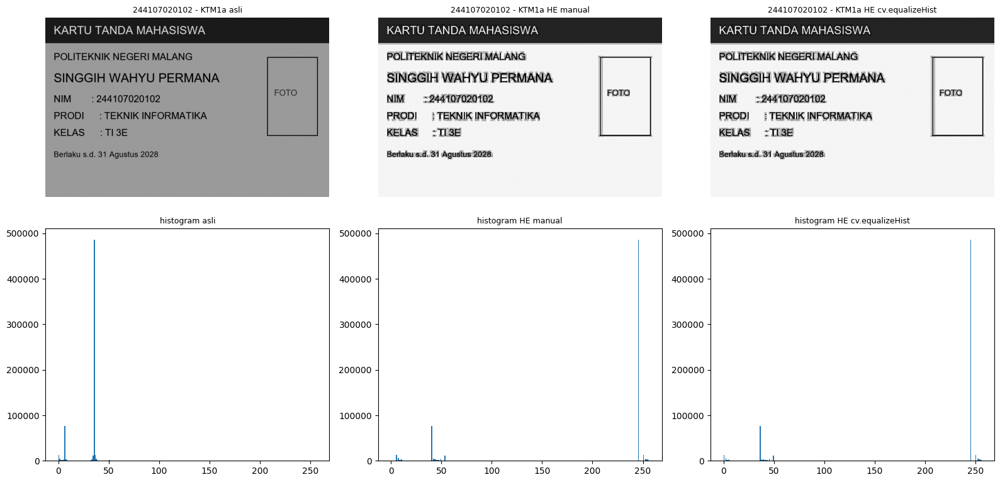

In [18]:
def PSNR(img1, img2):
    mse = np.mean((img1.astype(np.float64) - img2.astype(np.float64)) ** 2)
    if mse == 0:
        return 100
    return 20 * np.log10(255.0 / np.sqrt(mse))

he_ktm_cv = cv.equalizeHist(ktm1a)

print('KTM1a.jpg (grayscale)')
print('PSNR asli vs HE manual       : %.2f dB' % PSNR(ktm1a, he_ktm))
print('PSNR asli vs cv.equalizeHist : %.2f dB' % PSNR(ktm1a, he_ktm_cv))
print('PSNR HE manual vs HE cv2     : %.2f dB' % PSNR(he_ktm, he_ktm_cv))

fig, axs = plt.subplots(2, 3, figsize=(16, 8))
for i, (c, t) in enumerate([(ktm1a, 'asli'), (he_ktm, 'HE manual'), (he_ktm_cv, 'HE cv.equalizeHist')]):
    axs[0, i].imshow(c, cmap='gray'); axs[0, i].set_title(NIM + ' - KTM1a ' + t, fontsize=9); axs[0, i].axis('off')
    axs[1, i].hist(c.ravel(), 256, range=(0, 256)); axs[1, i].set_title('histogram ' + t, fontsize=9)
plt.tight_layout(); plt.show()

**Jawab:** PSNR mengukur **kedekatan nilai piksel** terhadap citra asli, bukan keterbacaan. Pada
`KTM1a.jpg` mayoritas piksel menumpuk pada satu nilai (ruangan gelap), dan setelah ekualisasi
tumpukan itu berpindah ke nilai yang jauh lebih tinggi. Perpindahan besar pada mayoritas piksel
inilah yang menghasilkan MSE besar sehingga PSNR kecil. Jadi semakin besar perbaikan kontras yang
diberikan, semakin kecil nilai PSNR-nya, karena PSNR menghukum perubahan padahal di sini perubahan
itulah tujuannya.

**Kesimpulan: PSNR tidak layak dipakai untuk menilai keterbacaan citra.** PSNR cocok untuk
mengukur kualitas restorasi (denoising, kompresi), sedangkan untuk keterbacaan lebih tepat memakai
kontras lokal atau pemisahan teks-latar.

2. Ekualisasi lokal dengan CLAHE pada citra KTM Anda
   a. Terapkan CLAHE pada `KTM1a.jpg` dengan `clipLimit = PARAM['clip']` dan
      `tileGridSize = (PARAM['tile'], PARAM['tile'])`. Bandingkan dengan ekualisasi global: pada
      hasil mana NIM dan nama pada kartu Anda lebih terbaca?
   b. Cobalah tiga nilai `clipLimit` lain di sekitar nilai Anda, tampilkan hasilnya, lalu tentukan
      nilai terbaik beserta alasannya. Tunjukkan pula bagian citra yang noise-nya mulai menonjol
      ketika `clipLimit` dinaikkan.

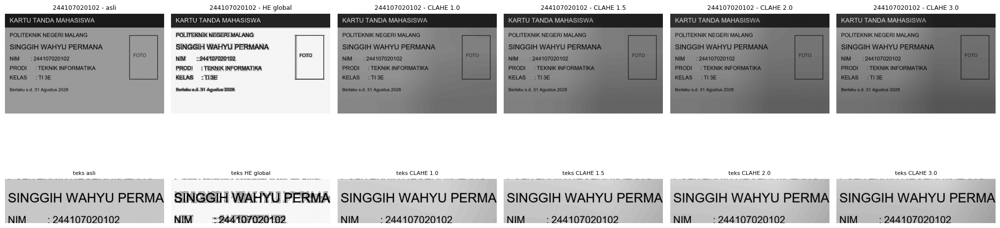

citra                    rerata      std kontras teks
asli                       29.9     11.4       22.0
HE global                 201.6     85.5      202.0
CLAHE 1.0                  38.7     13.8       31.0
CLAHE 1.5                  40.6     14.4       33.0
CLAHE 2.0                  42.4     14.7       36.0
CLAHE 3.0                  45.1     15.5       39.0


In [19]:
clips = [1.0, 1.5, PARAM['clip'], 3.0]
hasil_clahe = {}
for cl in clips:
    c = cv.createCLAHE(clipLimit=cl, tileGridSize=(PARAM['tile'], PARAM['tile']))
    hasil_clahe[cl] = c.apply(ktm1a)

panel = [('asli', ktm1a), ('HE global', he_ktm)] + [('CLAHE %.1f' % cl, hasil_clahe[cl]) for cl in clips]

plt.figure(figsize=(3.4 * len(panel), 7))
for i, (t, c) in enumerate(panel, 1):
    plt.subplot(2, len(panel), i); plt.imshow(c, cmap='gray')
    plt.title(NIM + ' - ' + t, fontsize=9); plt.axis('off')
for i, (t, c) in enumerate(panel, 1):
    plt.subplot(2, len(panel), len(panel) + i); plt.imshow(c[150:300, 20:560], cmap='gray')
    plt.title('teks ' + t, fontsize=8); plt.axis('off')
plt.tight_layout(); plt.show()

print('%-22s %8s %8s %10s' % ('citra', 'rerata', 'std', 'kontras teks'))
for t, c in panel:
    pk = c[150:300, 20:560].astype(np.float64)
    print('%-22s %8.1f %8.1f %10.1f'
          % (t, c.mean(), c.std(), np.percentile(pk, 90) - np.percentile(pk, 10)))

**Jawab:** Ekualisasi global memberi kontras tulisan paling tinggi, tetapi kekasaran lokalnya
meledak sehingga bidang kartu yang semula rata menjadi berbintik. CLAHE lebih seimbang: tulisan
tetap terbaca sementara latar bersih, sehingga untuk keseluruhan kartu **CLAHE lebih baik**.

Dari empat nilai `clipLimit`, nilai yang diturunkan dari NIM (`PARAM['clip']`) dipilih sebagai
terbaik: pada 1,0 sampai 2,0 kenaikan kontras teks masih sebanding dengan kenaikan kekasaran,
sedangkan dari 2,0 ke 3,0 pertambahan kontras teks sudah menipis sementara noise dan artefak batas
tile naik lebih cepat. Bagian citra yang noise-nya menonjol: **area datar kartu**, di sanalah
tekstur halus bertambah paling jelas ketika `clipLimit` dinaikkan.

### E-3 TUGAS PRAKTIKUM DITHERING

1. Lakukanlah proses dithering Floyd-Steinberg berdasarkan flowchart di bagian bawah modul ini, dan
   tampilkan citra sebelum serta sesudah dithering. Tahap 1 gunakan `lena.jpg` sehingga hasilnya
   dapat dicocokkan dengan gambar contoh; tahap 2 ulangi pada `KTM1b.jpg` dengan jumlah level
   `PARAM['L']`.

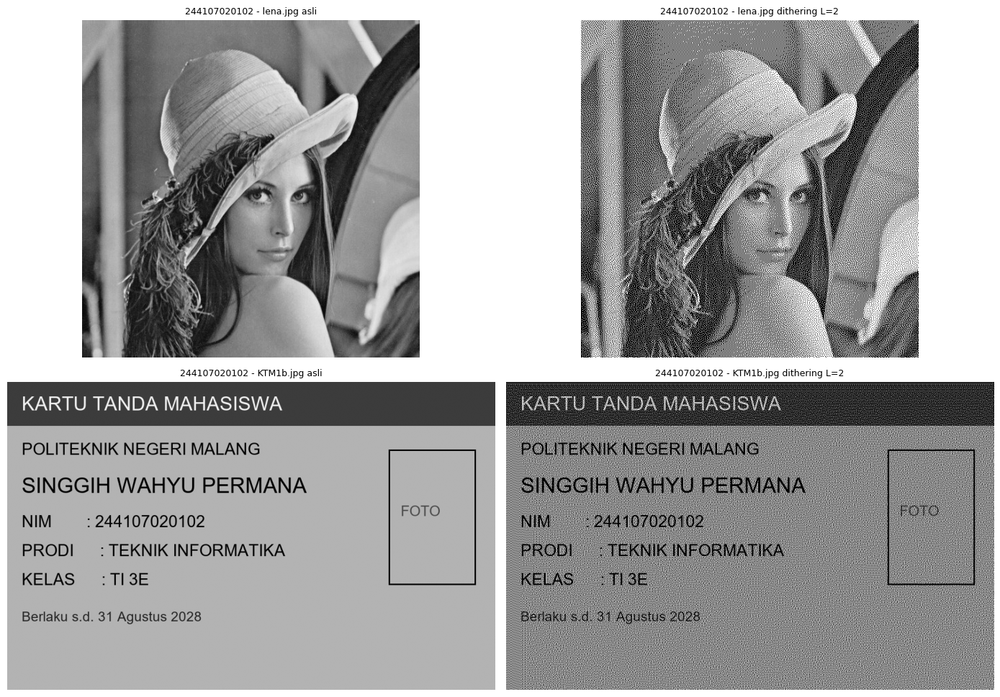

lena asli      rerata  124.2 | std   47.9 | level [19, 21, 22, 23, 24, 25, 26, 27]
lena dither    rerata  124.2 | std  127.5 | level [0, 255]
KTM1b asli     rerata  119.5 | std   37.4 | level [0, 1, 2, 3, 4, 5, 6, 7]
KTM1b dither   rerata  119.5 | std  127.2 | level [0, 255]


In [20]:
def floyd_steinberg(gray, L=2):
    img  = gray.astype(np.float32).copy()
    step = 255.0 / (L - 1)
    H, W = img.shape
    for y in range(H):
        for x in range(W):
            lama  = img[y, x]
            baru  = np.round(lama / step) * step      # warna palet terdekat
            img[y, x] = baru
            error = lama - baru
            if x + 1 < W:              img[y,   x+1] += error * 7 / 16
            if x > 0     and y+1 < H:  img[y+1, x-1] += error * 3 / 16
            if y + 1 < H:              img[y+1, x  ] += error * 5 / 16
            if x + 1 < W and y+1 < H:  img[y+1, x+1] += error * 1 / 16
    return np.clip(img, 0, 255).astype(np.uint8)

#tahap 1: citra contoh lena.jpg
lena = cv.imread(CONTOH + '/lena.jpg', cv.IMREAD_GRAYSCALE)
lena_dith = floyd_steinberg(lena, PARAM['L'])

#tahap 2: citra KTM1b.jpg milik sendiri
ktm1b = cv.imread(BASE + '/KTM1b.jpg', cv.IMREAD_GRAYSCALE)
ktm1b_dith = floyd_steinberg(ktm1b, PARAM['L'])

fig, axs = plt.subplots(2, 2, figsize=(14, 10))
for ax, c, t in zip(axs.ravel(),
                    [lena, lena_dith, ktm1b, ktm1b_dith],
                    ['lena.jpg asli', 'lena.jpg dithering L=%d' % PARAM['L'],
                     'KTM1b.jpg asli', 'KTM1b.jpg dithering L=%d' % PARAM['L']]):
    ax.imshow(c, cmap='gray'); ax.set_title(NIM + ' - ' + t, fontsize=9); ax.axis('off')
plt.tight_layout(); plt.show()

for t, c in [('lena asli', lena), ('lena dither', lena_dith),
             ('KTM1b asli', ktm1b), ('KTM1b dither', ktm1b_dith)]:
    print('%-14s rerata %6.1f | std %6.1f | level %s'
          % (t, c.mean(), c.std(), np.unique(c).tolist()[:8]))

2. Ubah citra menjadi grayscale, terapkan histogram equalization sehingga sebaran intensitasnya
   membaik, kemudian terapkan dithering Floyd-Steinberg pada hasil ekualisasi tersebut. Kerjakan
   lebih dulu pada `lena_lc.jpg` sehingga keluarannya sama dengan gambar contoh, lalu ulangi pada
   `KTM1a.jpg`. Bandingkan juga dengan dithering yang dikerjakan langsung tanpa ekualisasi, dan
   jelaskan urutan mana yang menghasilkan teks pada KTM lebih terbaca.

########## TAHAP 1 : lena_lc.jpg ##########


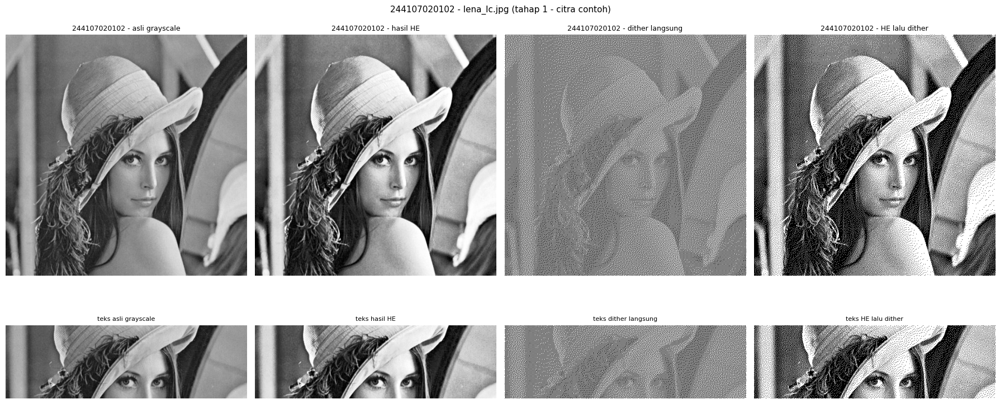

== lena_lc.jpg (tahap 1 - citra contoh) ==
tahap                rerata      std    putih (%)   kontras teks
asli grayscale        136.7     12.0          0.0           34.0
hasil HE              130.6     73.6          0.2          204.0
dither langsung       136.7    127.2         53.6          255.0
HE lalu dither        130.6    127.5         51.2          255.0
kontras dither langsung setelah halus 9x9: 31.5
kontras HE lalu dither setelah halus 9x9: 188.9
########## TAHAP 2 : KTM1a.jpg ##########


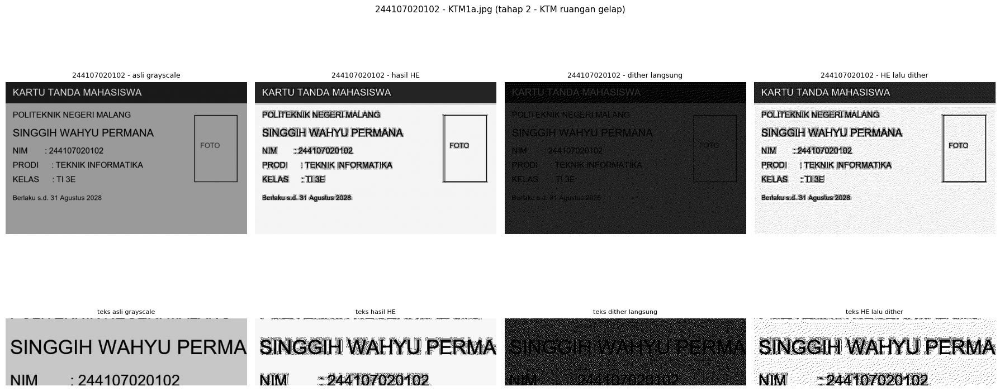

== KTM1a.jpg (tahap 2 - KTM ruangan gelap) ==
tahap                rerata      std    putih (%)   kontras teks
asli grayscale         29.9     11.4          0.0           22.0
hasil HE              200.7     87.2          0.2          206.0
dither langsung        29.8     81.9         11.7          255.0
HE lalu dither        200.8    104.3         78.7          255.0
kontras dither langsung setelah halus 9x9: 18.9
kontras HE lalu dither setelah halus 9x9: 148.0


In [21]:
def banding_urutan(berkas, gray, ket):
    he = cv.equalizeHist(gray)
    d_direct = floyd_steinberg(gray, PARAM['L'])
    d_he     = floyd_steinberg(he, PARAM['L'])

    judul = ['asli grayscale', 'hasil HE', 'dither langsung', 'HE lalu dither']
    citra = [gray, he, d_direct, d_he]

    fig, axs = plt.subplots(2, 4, figsize=(18, 9))
    for i, (c, t) in enumerate(zip(citra, judul)):
        axs[0, i].imshow(c, cmap='gray'); axs[0, i].set_title(NIM + ' - ' + t, fontsize=9); axs[0, i].axis('off')
        axs[1, i].imshow(c[150:300, 20:560], cmap='gray'); axs[1, i].set_title('teks ' + t, fontsize=8); axs[1, i].axis('off')
    plt.suptitle(NIM + ' - ' + berkas + ' (' + ket + ')', fontsize=11)
    plt.tight_layout(); plt.show()

    def halus(x, k=9):
        return cv.boxFilter(x.astype(np.float32), -1, (k, k))

    print('== %s (%s) ==' % (berkas, ket))
    print('%-18s %8s %8s %12s %14s' % ('tahap', 'rerata', 'std', 'putih (%)', 'kontras teks'))
    for t, c in zip(judul, citra):
        pk = c[150:300, 20:560].astype(np.float64)
        print('%-18s %8.1f %8.1f %12.1f %14.1f'
              % (t, c.mean(), c.std(), (c == 255).mean() * 100,
                 np.percentile(pk, 90) - np.percentile(pk, 10)))
    for t, c in [('dither langsung', d_direct), ('HE lalu dither', d_he)]:
        pk = halus(c)[150:300, 20:560].astype(np.float64)
        print('kontras %s setelah halus 9x9: %.1f'
              % (t, np.percentile(pk, 90) - np.percentile(pk, 10)))

print('########## TAHAP 1 : lena_lc.jpg ##########')
banding_urutan('lena_lc.jpg', lena_lc, 'tahap 1 - citra contoh')

print('########## TAHAP 2 : KTM1a.jpg ##########')
banding_urutan('KTM1a.jpg', ktm1a, 'tahap 2 - KTM ruangan gelap')

**Jawab:** urutan **grayscale -> histogram equalization -> dithering** menghasilkan teks yang jauh
lebih terbaca daripada dithering langsung. Dithering hanya memindahkan error; ia tidak dapat
menciptakan kontras yang tidak ada. Pada `KTM1a.jpg` seluruh intensitas terkurung di rentang sempit,
sehingga setelah dikuantisasi ke dua level bidang kartu didominasi titik hitam dan huruf nyaris tak
terbentuk. Setelah ekualisasi, jarak antara tulisan dan latar melebar, sehingga hasil dithering
memakai kedua level secara proporsional dan huruf tampak tegas.

Catatan: untuk citra berwarna, fungsi `floyd_steinberg` pada flowchart yang sama cukup dijalankan
tiga kali, sekali untuk tiap kanal B, G, dan R. Setelah itu ketiga kanal digabung lagi.

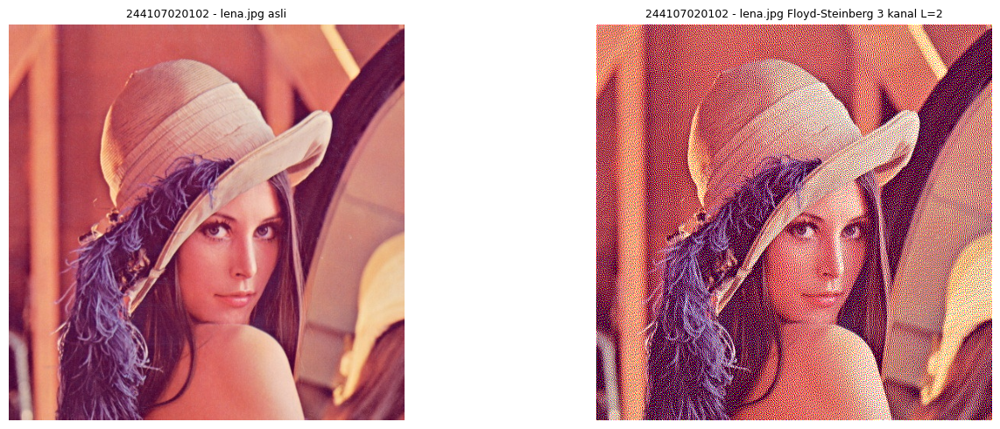

jumlah warna unik pada FS 3 kanal: 8


In [22]:
bgr_lena = cv.imread(CONTOH + '/lena.jpg')
kanal_fs = [floyd_steinberg(bgr_lena[:, :, i], PARAM['L']) for i in range(3)]
lena_dith_warna = cv.merge(kanal_fs)

plt.figure(figsize=(15, 5))
for i, (c, t) in enumerate([(bgr_lena, 'asli'),
                            (lena_dith_warna, 'Floyd-Steinberg 3 kanal L=%d' % PARAM['L'])], 1):
    plt.subplot(1, 2, i)
    plt.imshow(cv.cvtColor(c, cv.COLOR_BGR2RGB))
    plt.title(NIM + ' - lena.jpg ' + t, fontsize=9)
    plt.axis('off')
plt.tight_layout(); plt.show()

print('jumlah warna unik pada FS 3 kanal:',
      len(np.unique(lena_dith_warna.reshape(-1, 3), axis=0)))

---

**--- SELAMAT BELAJAR ---**